In [1]:
#MAJOR PROJECT-I---- SMART RETAIL ANALYTICS SYSTEM USING MACHINE LEARNING & MARKET BASKET ANALYSIS

In [2]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.metrics import mean_squared_error, accuracy_score, f1_score
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
warnings.filterwarnings('ignore')


In [3]:
#Load Dataset
df = pd.read_csv(r"G:\retail_sales_dataset.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [4]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [7]:
print(df.columns)

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')


In [8]:
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [9]:
#TO AVOID ANY ERRORS
# Convert numeric columns
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Price per Unit'] = pd.to_numeric(df['Price per Unit'], errors='coerce')
df['Tota Amount'] = pd.to_numeric(df['Total Amount'], errors='coerce')

# Convert IDs to string
df['Transaction ID'] = df['Transaction ID'].astype(str)
df['Customer ID'] = df['Customer ID'].astype(str)

# Convert Date if exists
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Drop missing values
df.dropna(inplace=True)

print("\nUpdated Data Types:")
print(df.dtypes)


Updated Data Types:
Transaction ID              object
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
Tota Amount                  int64
dtype: object


In [10]:
customer_df = df.groupby('Customer ID').agg({
    'Quantity': 'sum',
    'Total Amount': 'sum'
}).reset_index()

print(customer_df.head())

  Customer ID  Quantity  Total Amount
0     CUST001         3           150
1     CUST002         2          1000
2     CUST003         1            30
3     CUST004         1           500
4     CUST005         2           100


In [11]:
#CUSTOMER PURCHASE BEHAVIOUR
#Classification(customer segmentation)
scaler = StandardScaler()
scaled = scaler.fit_transform(customer_df[['Quantity', 'Total Amount']])

kmeans = KMeans(n_clusters=3, random_state=42)
customer_df['Cluster'] = kmeans.fit_predict(scaled)

print(customer_df.head())

  Customer ID  Quantity  Total Amount  Cluster
0     CUST001         3           150        0
1     CUST002         2          1000        2
2     CUST003         1            30        1
3     CUST004         1           500        1
4     CUST005         2           100        1


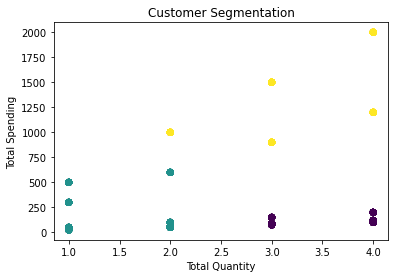

In [12]:
plt.scatter(customer_df['Quantity'],
            customer_df['Total Amount'],
            c=customer_df['Cluster'])

plt.xlabel("Total Quantity")
plt.ylabel("Total Spending")
plt.title("Customer Segmentation")
plt.show()

In [13]:
#LINEAR REGRESSION(Sales Prediction)
X=df[['Transaction ID', 'Quantity', 'Price per Unit']]

In [14]:
Y=df[['Total Amount']]

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(
X, Y,
test_size=0.2,
random_state=42)

In [16]:
model = LinearRegression()
model.fit(X_train, Y_train)

LinearRegression()

In [17]:
Y_pred= model.predict(X_test)

In [18]:
print("MSE:", mean_squared_error(Y_test, Y_pred))

MSE: 41757.03586998728


In [19]:
#MARKET BASKET ANALYSIS
basket = (df.groupby(['Transaction ID', 'Product Category'])['Quantity']
          .sum().unstack().fillna(0))

basket = basket.applymap(lambda x: 1 if x > 0 else 0)

print(basket.head())

Product Category  Beauty  Clothing  Electronics
Transaction ID                                 
1                      1         0            0
10                     0         1            0
100                    0         0            1
1000                   0         0            1
101                    0         1            0


In [20]:
frequent_items = apriori(basket, min_support=0.02, use_colnames=True)
print(basket.shape)
print(frequent_items)


(1000, 3)
   support       itemsets
0    0.307       (Beauty)
1    0.351     (Clothing)
2    0.342  (Electronics)


In [21]:
frequent_items['length'] = frequent_items['itemsets'].apply(len)
print(frequent_items)

   support       itemsets  length
0    0.307       (Beauty)       1
1    0.351     (Clothing)       1
2    0.342  (Electronics)       1


In [22]:
popular_products = df['Product Category'].value_counts()

print(popular_products)

Clothing       351
Electronics    342
Beauty         307
Name: Product Category, dtype: int64


In [23]:
#RECOMMEND PRODUCT
def recommend_popular(n=1):
    return popular_products.head(n).index.tolist()

print("Top Recommended Products:", recommend_popular())

Top Recommended Products: ['Clothing']


In [24]:
#CLASSIFICATION OF CUSTOMERS
# Create customer summary
customer_df = df.groupby('Customer ID').agg({
    'Total Amount': 'sum',
    'Quantity': 'sum',
    'Customer ID': 'count'
})

# Rename columns
customer_df.columns = ['Total Spending', 'Total Quantity', 'Purchase Frequency']

customer_df.reset_index(inplace=True)

print(customer_df.head())

  Customer ID  Total Spending  Total Quantity  Purchase Frequency
0     CUST001             150               3                   1
1     CUST002            1000               2                   1
2     CUST003              30               1                   1
3     CUST004             500               1                   1
4     CUST005             100               2                   1


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    customer_df[['Total Spending', 'Total Quantity', 'Purchase Frequency']]
)

In [26]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)

customer_df['Cluster'] = kmeans.fit_predict(scaled_data)

print(customer_df.head())

  Customer ID  Total Spending  Total Quantity  Purchase Frequency  Cluster
0     CUST001             150               3                   1        0
1     CUST002            1000               2                   1        2
2     CUST003              30               1                   1        1
3     CUST004             500               1                   1        1
4     CUST005             100               2                   1        1


In [27]:
cluster_summary = customer_df.groupby('Cluster').mean()

print(cluster_summary)

         Total Spending  Total Quantity  Purchase Frequency
Cluster                                                    
0            126.453287        3.553633                 1.0
1            171.935123        1.434004                 1.0
2           1297.727273        3.204545                 1.0


In [28]:
# Find cluster ranking by spending
cluster_order = customer_df.groupby('Cluster')['Total Spending'].mean().sort_values().index

label_map = {
    cluster_order[0]: 'Low Value',
    cluster_order[1]: 'Medium Value',
    cluster_order[2]: 'High Value'
}

customer_df['Customer Type'] = customer_df['Cluster'].map(label_map)

print(customer_df.head())

  Customer ID  Total Spending  Total Quantity  Purchase Frequency  Cluster  \
0     CUST001             150               3                   1        0   
1     CUST002            1000               2                   1        2   
2     CUST003              30               1                   1        1   
3     CUST004             500               1                   1        1   
4     CUST005             100               2                   1        1   

  Customer Type  
0     Low Value  
1    High Value  
2  Medium Value  
3  Medium Value  
4  Medium Value  
